In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

# 1. Montar Google Drive
drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 2. Ruta del archivo (Ajusta 'RML2016.10a_dict.pkl' a tu ubicación real)
path = '/content/drive/MyDrive/Seminario/RML2016.10a_dict.pkl'

with open(path, 'rb') as f:
    # El dataset está en Python 2, usamos latin1 para compatibilidad
    data = pickle.load(f, encoding='latin1')

# Extraer las llaves (Modulación, SNR)
keys = sorted(data.keys())
mods, snrs = map(lambda x: sorted(list(set(x))), zip(*keys))

print(f"Modulaciones detectadas: {mods}")
print(f"Niveles de SNR: {snrs}")

Modulaciones detectadas: ['8PSK', 'AM-DSB', 'AM-SSB', 'BPSK', 'CPFSK', 'GFSK', 'PAM4', 'QAM16', 'QAM64', 'QPSK', 'WBFM']
Niveles de SNR: [-20, -18, -16, -14, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18]


In [ ]:
type(data)

dict

In [ ]:
X = []
lbl = []

# Extraemos solo las señales con SNR alto (p.e. >= 10dB) para ver el potencial del modelo
# O puedes usar todas para un reto mayor
for mod, snr in data.keys():
  for signal in data[(mod, snr)]:
           X.append(signal)
           lbl.append(mod)

X = np.array(X)
lbl = np.array(lbl)

In [ ]:
X.shape

(220000, 2, 128)

#Preprocesamiento de Datos:
k-NN no entiende de dimensiones temporales, así que transformaremos los datos en un formato matricial estándar de Scikit-Learn ($N$ muestras, $M$ características).

Para que k-NN funcione eficientemente en radiocomunicaciones, debemos aplanar la matriz de $(2, 128)$ a un vector de $256$ dimensiones

In [ ]:
X = []
lbl = []

# Extraemos solo las señales con SNR alto (p.e. >= 10dB) para ver el potencial del modelo
# O puedes usar todas para un reto mayor
for mod, snr in data.keys():
    if snr == 18:
        for signal in data[(mod, snr)]:
            X.append(signal)
            lbl.append(mod)

X = np.array(X)
lbl = np.array(lbl)

# Paso crucial: Aplanar (Reshape) de (N, 2, 128) a (N, 256)
X_flatten = X.reshape(X.shape[0], -1)

print(f"Forma de X aplanada: {X_flatten.shape}")

Forma de X aplanada: (11000, 256)


En el mundo de las radiocomunicaciones, pasar de los datos crudos (Raw IQ) a características estadísticas (Handcrafted Features) es lo que separa a un sistema mediocre de uno profesional, especialmente cuando el ruido (SNR bajo) empieza a dominar la señal.

Al usar k-NN, el modelo sufre con el ruido porque este desplaza los puntos en el espacio de 256 dimensiones de forma aleatoria. Si extraemos la media, varianza, curtosis y sesgo de la amplitud y la fase, reducimos el ruido y resaltamos la "personalidad" de cada modulación.

In [ ]:
import pandas as pd
from scipy.stats import kurtosis, skew

def extract_features(iq_data):
    """
    Recibe un array de (N, 2, 128) y devuelve un array de características (N, features)
    """
    num_samples = iq_data.shape[0]
    features = []

    for i in range(num_samples):
        I = iq_data[i, 0, :]
        Q = iq_data[i, 1, :]

        # Calcular Amplitud y Fase
        ampl = np.sqrt(I**2 + Q**2)
        phase = np.arctan2(Q, I)

        # Extraer estadísticos
        feat = [
            np.mean(ampl), np.var(ampl), skew(ampl), kurtosis(ampl),
            np.mean(phase), np.var(phase), skew(phase), kurtosis(phase)
        ]
        features.append(feat)

    return np.array(features)

# Aplicar extracción
X_feats = extract_features(X)
print(f"Nueva forma de los datos: {X_feats.shape}") # Ahora cada señal se resume en 8 valores

Nueva forma de los datos: (11000, 8)


Entrenamiento del k-NN con Características Mejoradas
Ahora repetimos el proceso de entrenamiento. Al tener solo 8 características muy potentes, el k-NN será órdenes de magnitud más rápido y, usualmente, más preciso.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# 1. División
X_train_f, X_test_f, y_train, y_test = train_test_split(X_feats, lbl, test_size=0.3, random_state=42)

# 2. Escalado (Fundamental para k-NN)
scaler = StandardScaler()
X_train_f = scaler.fit_transform(X_train_f)
X_test_f = scaler.transform(X_test_f)

# 3. Modelo
knn_expert = KNeighborsClassifier(n_neighbors=7, weights='distance')
knn_expert.fit(X_train_f, y_train)

# 4. Predicción
y_pred_f = knn_expert.predict(X_test_f)

SNR: -20 dB | Exactitud: 0.0917
SNR: -18 dB | Exactitud: 0.0914
SNR: -16 dB | Exactitud: 0.0915
SNR: -14 dB | Exactitud: 0.0923
SNR: -12 dB | Exactitud: 0.0977
SNR: -10 dB | Exactitud: 0.1075
SNR:  -8 dB | Exactitud: 0.1305
SNR:  -6 dB | Exactitud: 0.1480
SNR:  -4 dB | Exactitud: 0.1809
SNR:  -2 dB | Exactitud: 0.2698
SNR:   0 dB | Exactitud: 0.3395
SNR:   2 dB | Exactitud: 0.4154
SNR:   4 dB | Exactitud: 0.4992
SNR:   6 dB | Exactitud: 0.5507
SNR:   8 dB | Exactitud: 0.5725
SNR:  10 dB | Exactitud: 0.6206
SNR:  12 dB | Exactitud: 0.6598
SNR:  14 dB | Exactitud: 0.6818
SNR:  16 dB | Exactitud: 0.6903
SNR:  18 dB | Exactitud: 0.9049


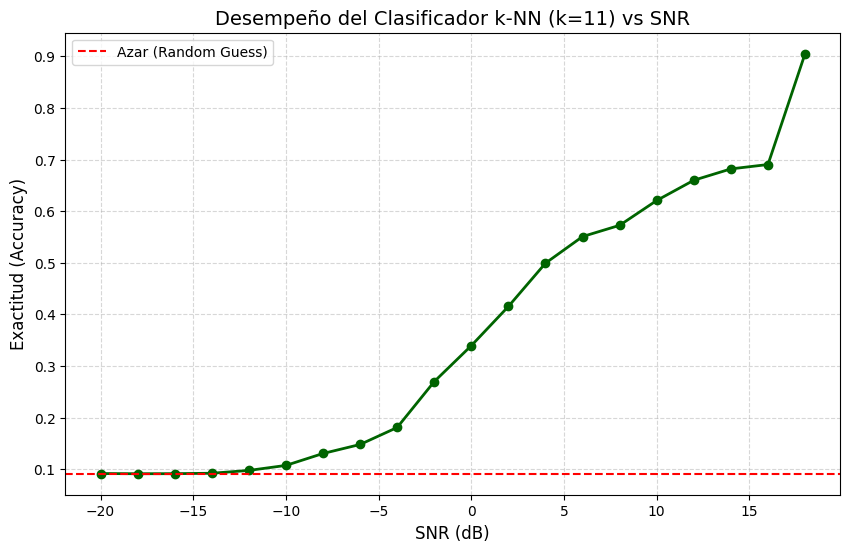

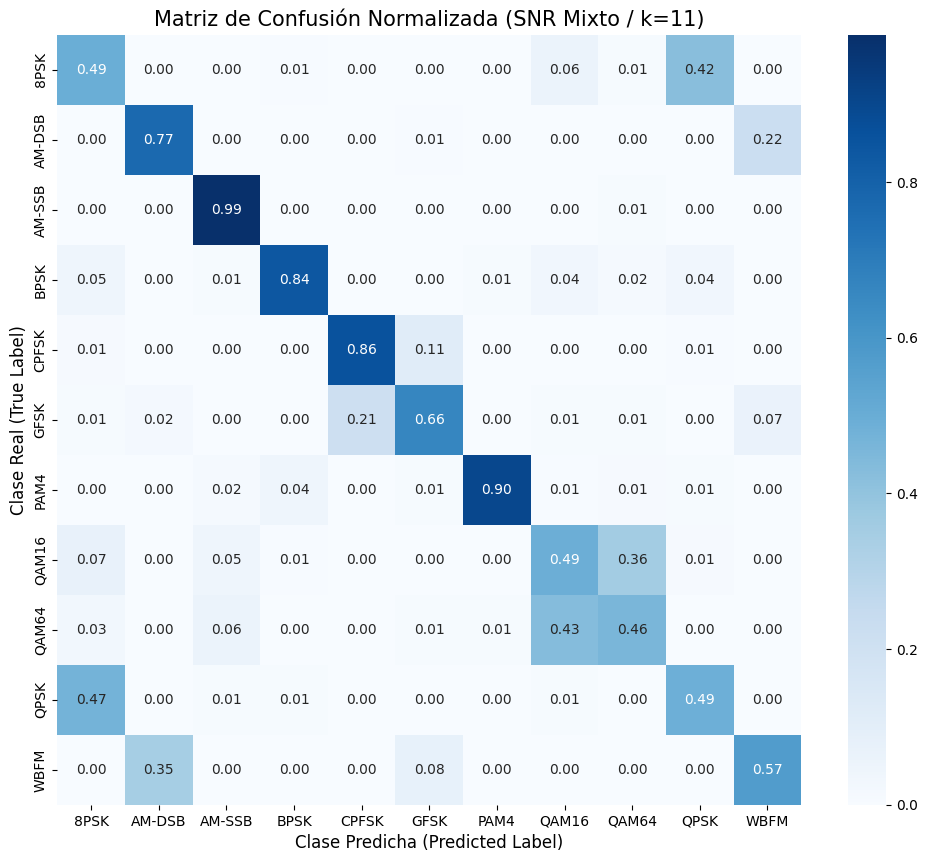

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Definir el mejor k
best_k = 11
knn_final = KNeighborsClassifier(n_neighbors=best_k, weights='distance', n_jobs=-1)
knn_final.fit(X_train_f, y_train)

# 2. Preparar la evaluación por SNR
acc_per_snr = {}
snrs = sorted(list(set([k[1] for k in data.keys()])))

for snr in snrs:
    X_snr = []
    lbl_snr = []

    # Extraer datos específicos para este SNR
    for mod in mods:
        for signal in data[(mod, snr)]:
            X_snr.append(signal)
            lbl_snr.append(mod)

    X_snr = np.array(X_snr)

    # Extraer características (usando la función avanzada de tiempo+frecuencia)
    X_feats_snr = extract_features(X_snr)

    # Escalar (usando el scaler entrenado originalmente)
    X_feats_snr = scaler.transform(X_feats_snr)

    # Predecir y calcular precisión
    y_pred_snr = knn_final.predict(X_feats_snr)
    acc = accuracy_score(lbl_snr, y_pred_snr)
    acc_per_snr[snr] = acc

    print(f"SNR: {snr:3d} dB | Exactitud: {acc:.4f}")

# --- 3. Graficar la Curva de Desempeño ---
plt.figure(figsize=(10, 6))
plt.plot(snrs, [acc_per_snr[s] for s in snrs], marker='o', linewidth=2, color='darkgreen')
plt.title(f'Desempeño del Clasificador k-NN (k={best_k}) vs SNR', fontsize=14)
plt.xlabel('SNR (dB)', fontsize=12)
plt.ylabel('Exactitud (Accuracy)', fontsize=12)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.axhline(y=1/len(mods), color='r', linestyle='--', label='Azar (Random Guess)') # Nivel de azar
plt.legend()
plt.show()
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Generar predicciones para el set de prueba final (puedes usar el X_test_f que ya tienes)
y_pred_final = knn_final.predict(X_test_f)

# 2. Calcular la matriz de confusión
# 'mods' contiene las etiquetas de las modulaciones
cm = confusion_matrix(y_test, y_pred_final, labels=mods)

# 3. Normalizar la matriz para ver porcentajes (opcional pero muy recomendado)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# 4. Graficar
plt.figure(figsize=(12, 10))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap='Blues',
            xticklabels=mods, yticklabels=mods)

plt.title(f'Matriz de Confusión Normalizada (SNR Mixto / k={best_k})', fontsize=15)
plt.ylabel('Clase Real (True Label)', fontsize=12)
plt.xlabel('Clase Predicha (Predicted Label)', fontsize=12)
plt.show()